<a href="https://colab.research.google.com/github/avaabarnes/L03-tree-stability/blob/main/L3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Trees and Model Stability

Trees are notorious for being **unstable**: Small changes in the data can lead to noticeable or large changes in the tree. We're going to explore this phenomenon.

1. Check out the data set `heart_failure` and appropriately clean it.
2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.
3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.
4. Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial.
But are they? Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?

5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?
6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Ava Barnes, Maggie Wetmore, Rebecca Hobson

**Date:** 16 November 2026

In [ ]:
# Your Phase 1 solution to the problem goes here.


#1.

In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv('/content/heart_failure_clinical_records_dataset (2).csv')

#Investigate Data
print(df.shape)
print(df.dtypes)
display(df.head(20))
print('\nduplicates:', df.duplicated().sum())
print('\nmissing:', df.isna().sum())

#no missing values or duplicate rows
#all variables are numeric

#Select predictors and target variable
features = ['age', 'anaemia', 'creatinine_phosphokinase',
            'diabetes', 'ejection_fraction', 'high_blood_pressure',
            'platelets', 'serum_creatinine', 'serum_sodium',
            'sex', 'smoking'] #excluded 'time'


(299, 13)
age                         float64
anaemia                       int64
creatinine_phosphokinase      int64
diabetes                      int64
ejection_fraction             int64
high_blood_pressure           int64
platelets                   float64
serum_creatinine            float64
serum_sodium                  int64
sex                           int64
smoking                       int64
time                          int64
DEATH_EVENT                   int64
dtype: object


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1
5,90.0,1,47,0,40,1,204000.00,2.1,132,1,1,8,1
6,75.0,1,246,0,15,0,127000.00,1.2,137,1,0,10,1
7,60.0,1,315,1,60,0,454000.00,1.1,131,1,1,10,1
8,65.0,0,157,0,65,0,263358.03,1.5,138,0,0,10,1
9,80.0,1,123,0,35,1,388000.00,9.4,133,1,1,10,1



duplicates: 0

missing: age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creatinine            0
serum_sodium                0
sex                         0
smoking                     0
time                        0
DEATH_EVENT                 0
dtype: int64


#2.

Train RMSE: 0.40286715437274595
Test RMSE: 0.44244474934454103
Train R-squared: 0.2567861674395374
Test R-squared: 0.09534469524878886


,Actual,Linear,Tree
78,0,0.405815,1
125,0,0.093226,0
288,0,0.382734,1
295,0,0.338811,0
102,0,0.578677,1


Train Accuracy: 1.0
Linear Test Accuracy: 0.75
Tree Test Accuracy: 0.5666666666666667
Predicted   0   1
Actual           
0          25  16
1          10   9


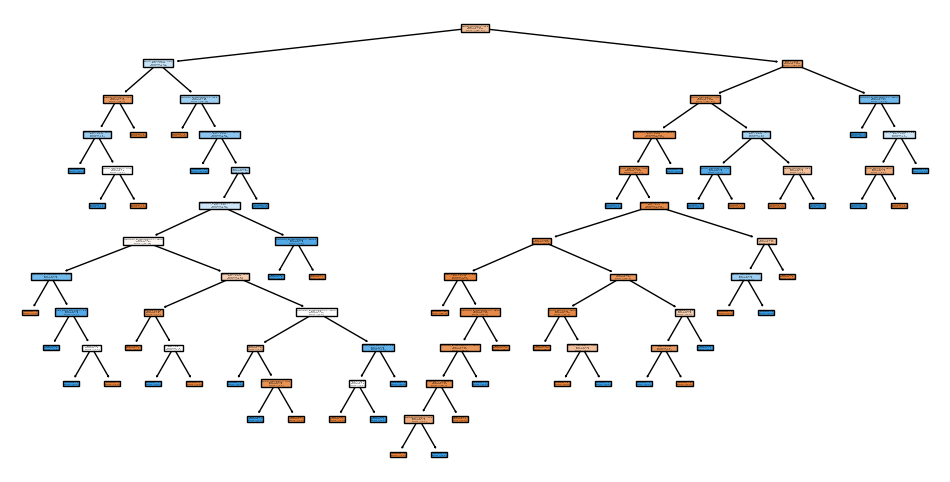

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

X = df[features]
y = df['DEATH_EVENT']

#Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=83, shuffle=True, stratify=y)

#Run model
sk_fit_1 = LinearRegression().fit(X_train, y_train)

#Predict on train and test
train_pred = sk_fit_1.predict(X_train)
test_pred = sk_fit_1.predict(X_test)

#Find RMSE and R^2, test and train
print("Train RMSE:", np.sqrt(np.mean((y_train - train_pred)**2)))
print("Test RMSE:", np.sqrt(np.mean((y_test - test_pred)**2)))
print("Train R-squared:", sk_fit_1.score(X_train, y_train))
print("Test R-squared:", sk_fit_1.score(X_test, y_test))

#Fit decision tree
tree = DecisionTreeClassifier(random_state=83).fit(X_train, y_train)

#Predict on train and test data
tree_train_pred = tree.predict(X_train)
tree_test_pred = tree.predict(X_test)

#Set aside test predictions from both models
predictions_83 = pd.DataFrame({
    'Actual': y_test,
    'Linear': test_pred,
    'Tree': tree_test_pred
}, index=y_test.index)

display(predictions_83.head())

#Evaluate tree
print("Train Accuracy:", tree.score(X_train, y_train))

#Compare test accuracy of both models
linear_class_pred = (test_pred >= 0.5).astype(int)

print("Linear Test Accuracy:", np.mean(y_test == linear_class_pred))
print("Tree Test Accuracy:", tree.score(X_test, y_test))

#Compare actual and predicted outcomes
print(pd.crosstab(y_test, tree_test_pred,
                  rownames=["Actual"],
                  colnames=["Predicted"]))

#Visualize decision tree
plt.figure(figsize=(12, 6))
plot_tree(tree, feature_names=features, filled=True)
plt.show()

#3.


Seed: 24
Linear R-squared: 0.22430047541239473
Tree Accuracy: 0.6833333333333333
Tree Depth: 11
Tree Leaves: 47
Linear Accuracy: 0.7333333333333333


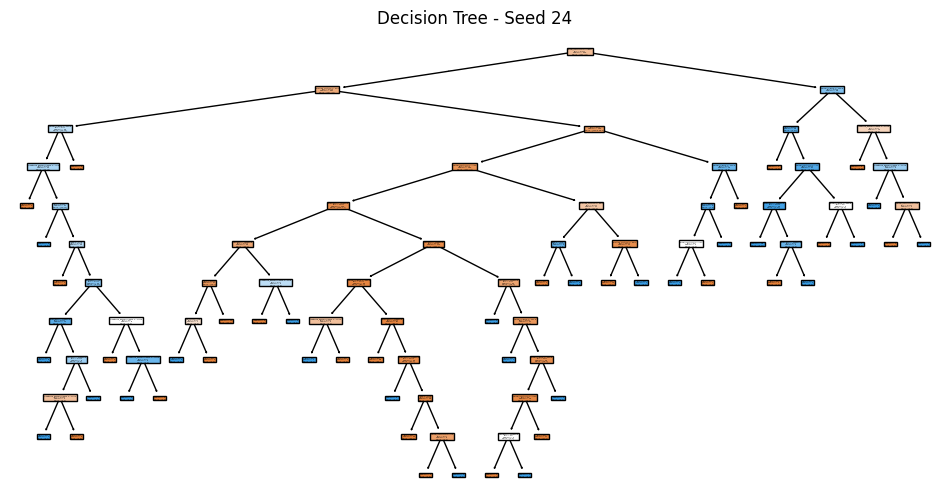


Seed: 48
Linear R-squared: 0.309031479274282
Tree Accuracy: 0.6833333333333333
Tree Depth: 11
Tree Leaves: 52
Linear Accuracy: 0.7666666666666667


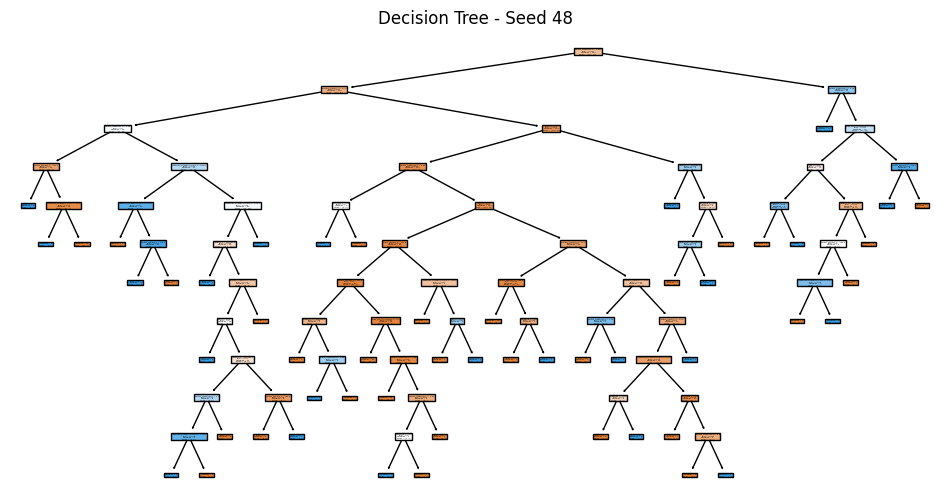


Seed: 72
Linear R-squared: 0.07434278896009627
Tree Accuracy: 0.6166666666666667
Tree Depth: 12
Tree Leaves: 43
Linear Accuracy: 0.7166666666666667


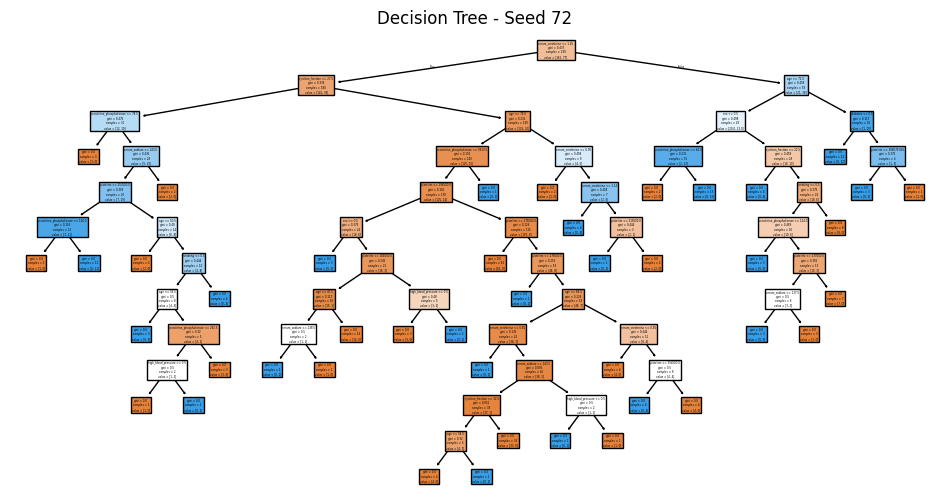


Seed: 96
Linear R-squared: 0.15540587219083923
Tree Accuracy: 0.7
Tree Depth: 13
Tree Leaves: 52
Linear Accuracy: 0.6833333333333333


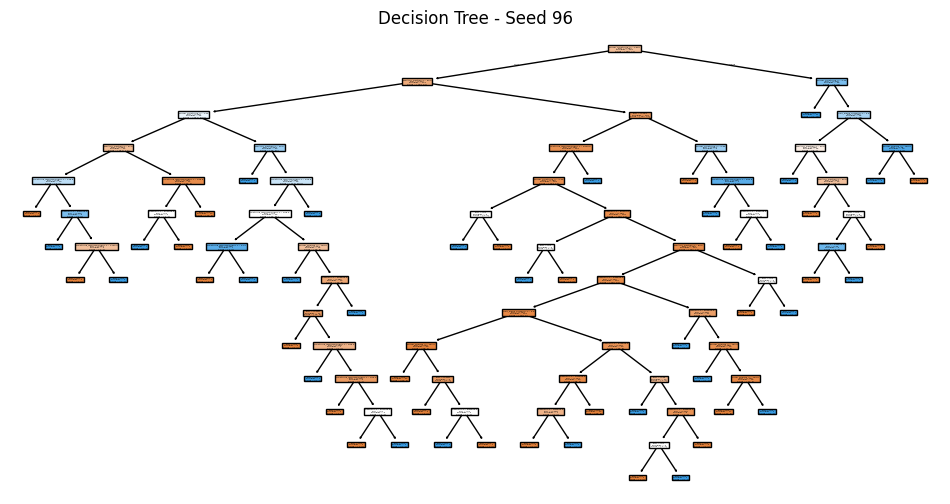


Linear Regression Coefficients:


,83,24,48,72,96
age,9.107331e-03,9.694243e-03,8.053456e-03,8.770096e-03,7.954463e-03
anaemia,6.368067e-02,6.981866e-02,6.363805e-02,4.743288e-02,2.021403e-02
creatinine_phosphokinase,5.131699e-05,2.999090e-05,3.040343e-05,4.383654e-05,5.665039e-05
diabetes,-1.938742e-02,9.739200e-03,3.728032e-02,-2.889671e-03,-1.033896e-02
ejection_fraction,-1.267399e-02,-9.915336e-03,-9.866511e-03,-1.186088e-02,-1.113791e-02
high_blood_pressure,6.354626e-02,2.400316e-02,8.587866e-02,9.607757e-02,9.577999e-02
platelets,-1.528211e-07,-1.340927e-08,-1.513024e-07,-1.489522e-07,-9.766555e-08
serum_creatinine,1.043169e-01,9.040317e-02,1.134035e-01,1.025758e-01,1.102818e-01
serum_sodium,-2.915296e-03,-1.151676e-02,-1.021012e-02,-8.001961e-03,-1.093299e-02
sex,-1.187698e-01,-1.105426e-02,-7.403496e-02,-1.234228e-01,-6.045708e-02


In [ ]:
#Repeat models with different seeds
seeds = [24, 48, 72, 96]

#Save original models and predictions from Step 2 (seed 83)
linear_models = {83: sk_fit_1}
trees = {83: tree}
predictions = {83: predictions_83}

for seed in seeds:

    #Train-test split
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=seed,
        shuffle=True, stratify=y)

    #Fit linear model
    linear = LinearRegression().fit(X_train, y_train)

    #Fit decision tree
    tree = DecisionTreeClassifier(random_state=seed).fit(X_train, y_train)

    #Save models and test predictions
    linear_models[seed] = linear
    trees[seed] = tree

    predictions[seed] = pd.DataFrame({
        'Actual': y_test,
        'Linear': linear.predict(X_test),
        'Tree': tree.predict(X_test)
    }, index=y_test.index)

    #Compare performance
    print("\nSeed:", seed)
    print("Linear R-squared:", linear.score(X_test, y_test))
    print("Tree Accuracy:", tree.score(X_test, y_test))
    print("Tree Depth:", tree.get_depth())
    print("Tree Leaves:", tree.get_n_leaves())

    #Compare test accuracy of both models
    linear_class_pred = (linear.predict(X_test) >= 0.5).astype(int)
    print("Linear Accuracy:", np.mean(y_test == linear_class_pred))

    #Visualize decision tree for each seed
    plt.figure(figsize=(12, 6))
    plot_tree(tree, feature_names=features, filled=True)
    plt.title("Decision Tree - Seed " + str(seed))
    plt.show()

#Compare linear regression coefficients across all five seeds
coefficients = pd.DataFrame({
    seed: model.coef_
    for seed, model in linear_models.items()
}, index=features)

print("\nLinear Regression Coefficients:")
display(coefficients)

We repeated the models using five different random seeds and found that the decision trees varied signifigantly in their structure and performance. The depths of the decision trees ranged from 11 to 13, with 43 to 52 leaves, and the test accuracy ranged from 56.67% to 70%. The linear regression coefficients were more consistent overall, but especially for age, ejection fraction, and serum creatinine. Although some coefficients such as diabetes and smoking, changed signs across seeds. Ultimately, the results suggest that the decision trees were sensitive to changes in the training data, while several of the linear regression coefficients remained relatively stable.

#4.

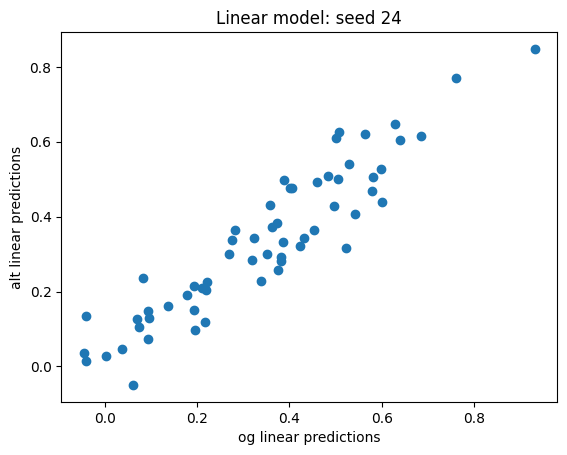

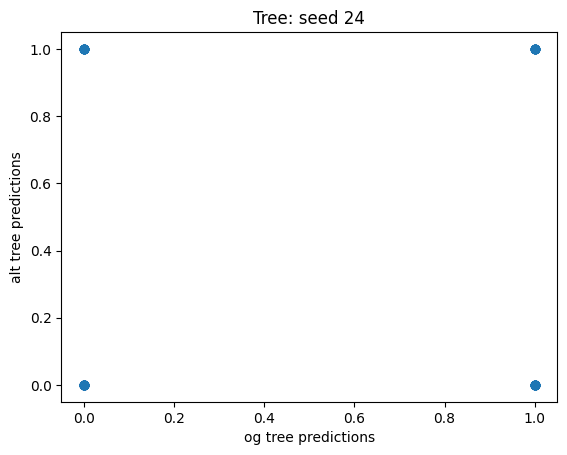

Linear correlation: 0.9282402987357011
Tree correlation: 0.04780914437337572
Linear intercept: 0.0391
Linear slope: 0.8584
Linear R-squared: 0.8616
Tree intercept: 0.3143
Tree slope: 0.0457
Tree R-squared: 0.0023


In [ ]:
#recover the og split from # 2
X_train_og, X_test_og, y_train_og, y_test_og = train_test_split(
    X, y, test_size=0.20, random_state=83,
    shuffle=True, stratify=y)
#recover the og tree
tree_og = DecisionTreeClassifier(random_state=83).fit(
    X_train_og, y_train_og)
#save og predictions on the og test patients
linear_og_pred = sk_fit_1.predict(X_test_og)
tree_og_pred = tree_og.predict(X_test_og)
#put og predictions into predictor columns for 4c
linear_og_X = pd.DataFrame({"og": linear_og_pred})
tree_og_X = pd.DataFrame({"og": tree_og_pred})
#compare each alt model with the og model
for seed in seeds:
  seed = 24
#predict for the same patients in the same order
linear_alt_pred = linear_models[seed].predict(X_test_og)
tree_alt_pred = trees[seed].predict(X_test_og)
#a- scatterplot of og and alt linear predictions
plt.scatter(linear_og_pred, linear_alt_pred)
plt.xlabel("og linear predictions")
plt.ylabel("alt linear predictions")
plt.title("Linear model: seed " + str(seed))
plt.show()
#a- scatterplot of og and alt tree predictions
plt.scatter(tree_og_pred, tree_alt_pred)
plt.xlabel("og tree predictions")
plt.ylabel("alt tree predictions")
plt.title("Tree: seed " + str(seed))
plt.show()
#b- correlation between og and alt linear predictions
print("Linear correlation:",
pd.Series(linear_og_pred).corr(pd.Series(linear_alt_pred)))
#b- correlation between og and alt tree predictions
print("Tree correlation:",
pd.Series(tree_og_pred).corr(pd.Series(tree_alt_pred)))
#c- regress alt linear predictions on og linear predictions
linear_fit = LinearRegression().fit(
linear_og_X, linear_alt_pred)
print("Linear intercept:", round(linear_fit.intercept_, 4))
print("Linear slope:", round(linear_fit.coef_[0], 4))
print("Linear R-squared:", round(linear_fit.score(linear_og_X, linear_alt_pred), 4))
#c- regress alt tree predictions on og tree predictions
tree_fit = LinearRegression().fit(tree_og_X, tree_alt_pred)
print("Tree intercept:", round(tree_fit.intercept_, 4))
print("Tree slope:", round(tree_fit.coef_[0], 4))
print("Tree R-squared:",
round(tree_fit.score(tree_og_X, tree_alt_pred), 4))

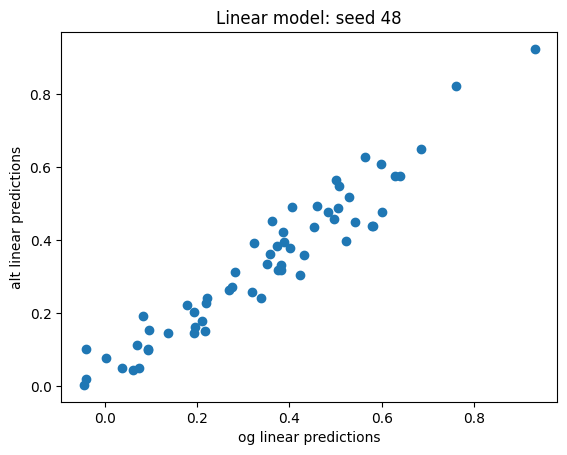

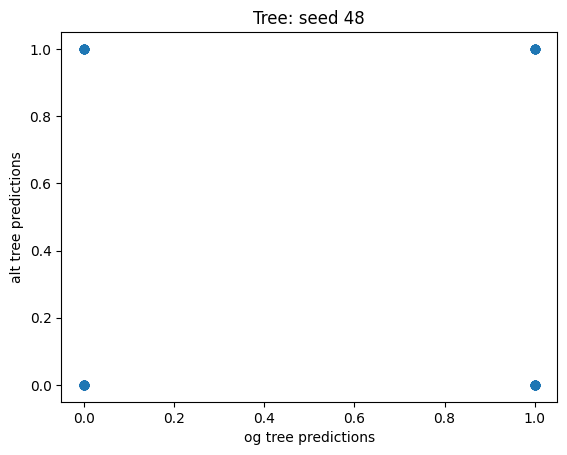

Linear correlation: 0.9577200534384543
Tree correlation: 0.04780914437337572
Linear intercept: 0.0334
Linear slope: 0.8837
Linear R-squared: 0.9172
Tree intercept: 0.3143
Tree slope: 0.0457
Tree R-squared: 0.0023


In [ ]:
#compare each alt model with the og model #repeat of previous but with different seed
for seed in seeds:
  seed = 48
#predict for the same patients in the same order
linear_alt_pred = linear_models[seed].predict(X_test_og)
tree_alt_pred = trees[seed].predict(X_test_og)
#a- scatterplot of og and alt linear predictions
plt.scatter(linear_og_pred, linear_alt_pred)
plt.xlabel("og linear predictions")
plt.ylabel("alt linear predictions")
plt.title("Linear model: seed " + str(seed))
plt.show()
#a- scatterplot of og and alt tree predictions
plt.scatter(tree_og_pred, tree_alt_pred)
plt.xlabel("og tree predictions")
plt.ylabel("alt tree predictions")
plt.title("Tree: seed " + str(seed))
plt.show()
#b- correlation between og and alt linear predictions
print("Linear correlation:",
pd.Series(linear_og_pred).corr(pd.Series(linear_alt_pred)))
#b- correlation between og and alt tree predictions
print("Tree correlation:",
pd.Series(tree_og_pred).corr(pd.Series(tree_alt_pred)))
#c- regress alt linear predictions on og linear predictions
linear_fit = LinearRegression().fit(
linear_og_X, linear_alt_pred)
print("Linear intercept:", round(linear_fit.intercept_, 4))
print("Linear slope:", round(linear_fit.coef_[0], 4))
print("Linear R-squared:", round(linear_fit.score(linear_og_X, linear_alt_pred), 4))
#c- regress alt tree predictions on og tree predictions
tree_fit = LinearRegression().fit(tree_og_X, tree_alt_pred)
print("Tree intercept:", round(tree_fit.intercept_, 4))
print("Tree slope:", round(tree_fit.coef_[0], 4))
print("Tree R-squared:",
round(tree_fit.score(tree_og_X, tree_alt_pred), 4))

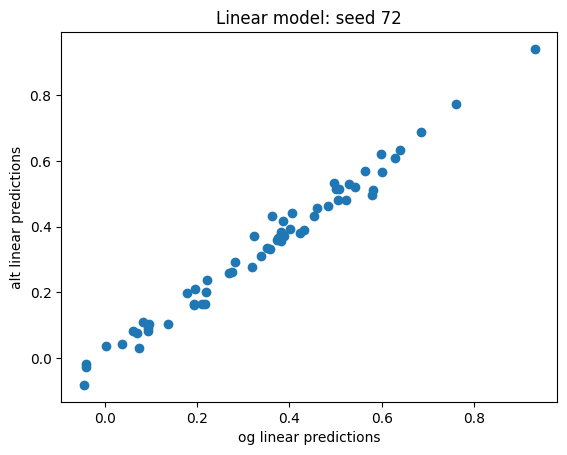

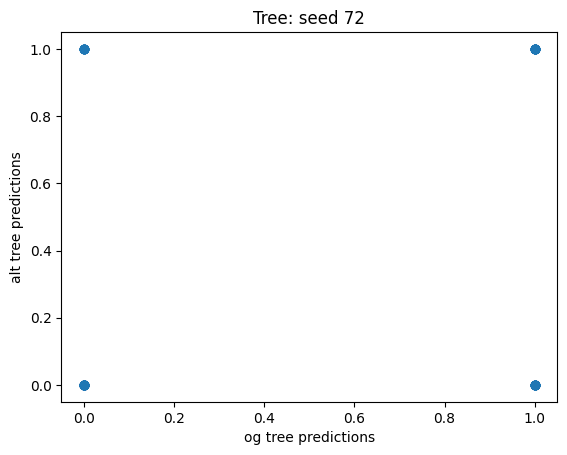

Linear correlation: 0.9908332910136983
Tree correlation: 0.2629502940535668
Linear intercept: -0.0019
Linear slope: 0.9835
Linear R-squared: 0.9818
Tree intercept: 0.2286
Tree slope: 0.2514
Tree R-squared: 0.0691


In [ ]:
#compare each alt model with the og model #repeat of previous but with different seed
for seed in seeds:
  seed = 72
#predict for the same patients in the same order
linear_alt_pred = linear_models[seed].predict(X_test_og)
tree_alt_pred = trees[seed].predict(X_test_og)
#a- scatterplot of og and alt linear predictions
plt.scatter(linear_og_pred, linear_alt_pred)
plt.xlabel("og linear predictions")
plt.ylabel("alt linear predictions")
plt.title("Linear model: seed " + str(seed))
plt.show()
#a- scatterplot of og and alt tree predictions
plt.scatter(tree_og_pred, tree_alt_pred)
plt.xlabel("og tree predictions")
plt.ylabel("alt tree predictions")
plt.title("Tree: seed " + str(seed))
plt.show()
#b- correlation between og and alt linear predictions
print("Linear correlation:",
pd.Series(linear_og_pred).corr(pd.Series(linear_alt_pred)))
#b- correlation between og and alt tree predictions
print("Tree correlation:",
pd.Series(tree_og_pred).corr(pd.Series(tree_alt_pred)))
#c- regress alt linear predictions on og linear predictions
linear_fit = LinearRegression().fit(
linear_og_X, linear_alt_pred)
print("Linear intercept:", round(linear_fit.intercept_, 4))
print("Linear slope:", round(linear_fit.coef_[0], 4))
print("Linear R-squared:", round(linear_fit.score(linear_og_X, linear_alt_pred), 4))
#c- regress alt tree predictions on og tree predictions
tree_fit = LinearRegression().fit(tree_og_X, tree_alt_pred)
print("Tree intercept:", round(tree_fit.intercept_, 4))
print("Tree slope:", round(tree_fit.coef_[0], 4))
print("Tree R-squared:",
round(tree_fit.score(tree_og_X, tree_alt_pred), 4))

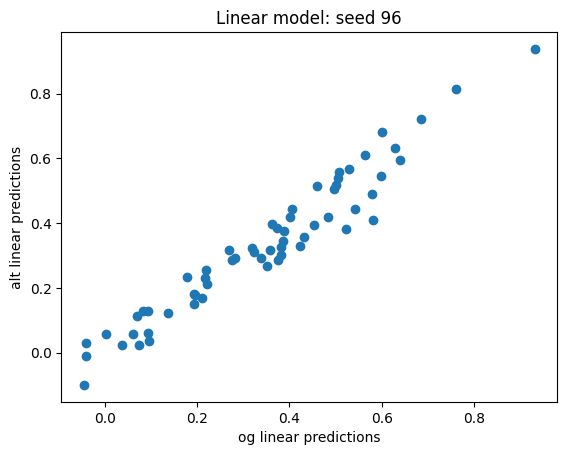

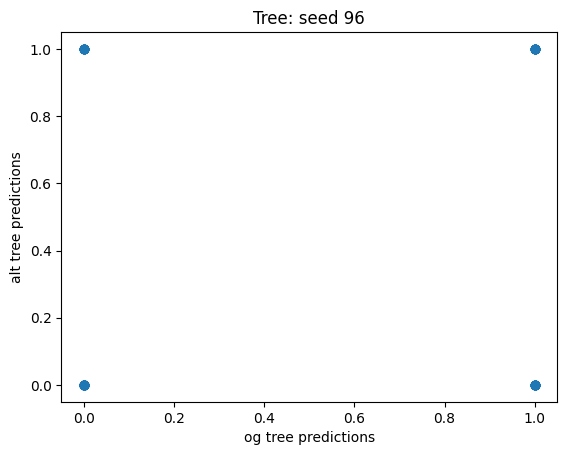

Linear correlation: 0.9676684019482878
Tree correlation: 0.15947323018612516
Linear intercept: 0.0002
Linear slope: 0.9651
Linear R-squared: 0.9364
Tree intercept: 0.2857
Tree slope: 0.1543
Tree R-squared: 0.0254


In [ ]:
#compare each alt model with the og model #repeat of previous but with different seed
for seed in seeds:
  seed = 96
#predict for the same patients in the same order
linear_alt_pred = linear_models[seed].predict(X_test_og)
tree_alt_pred = trees[seed].predict(X_test_og)
#a- scatterplot of og and alt linear predictions
plt.scatter(linear_og_pred, linear_alt_pred)
plt.xlabel("og linear predictions")
plt.ylabel("alt linear predictions")
plt.title("Linear model: seed " + str(seed))
plt.show()
#a- scatterplot of og and alt tree predictions
plt.scatter(tree_og_pred, tree_alt_pred)
plt.xlabel("og tree predictions")
plt.ylabel("alt tree predictions")
plt.title("Tree: seed " + str(seed))
plt.show()
#b- correlation between og and alt linear predictions
print("Linear correlation:",
pd.Series(linear_og_pred).corr(pd.Series(linear_alt_pred)))
#b- correlation between og and alt tree predictions
print("Tree correlation:",
pd.Series(tree_og_pred).corr(pd.Series(tree_alt_pred)))
#c- regress alt linear predictions on og linear predictions
linear_fit = LinearRegression().fit(
linear_og_X, linear_alt_pred)
print("Linear intercept:", round(linear_fit.intercept_, 4))
print("Linear slope:", round(linear_fit.coef_[0], 4))
print("Linear R-squared:", round(linear_fit.score(linear_og_X, linear_alt_pred), 4))
#c- regress alt tree predictions on og tree predictions
tree_fit = LinearRegression().fit(tree_og_X, tree_alt_pred)
print("Tree intercept:", round(tree_fit.intercept_, 4))
print("Tree slope:", round(tree_fit.coef_[0], 4))
print("Tree R-squared:",
round(tree_fit.score(tree_og_X, tree_alt_pred), 4))

4a. Original and alternative linear predictions appear very similar. The tree predictions disagree for some of the patients. Only 4 points appear because the tree predictions are 0 or 1 so many of the observations overlap.

4b. The linear predictions are highly correllated across the 4 fields at seed=24 it is .9282, seed=48 it is .9577, seed=72 it is .9908, seed=96 it is .9677. The tree predictions have a weak correlation at seed=24 it is .0478, seed=48 it is .0478, seed it is .263, seed=96 it is .1595.

4c. The linear models have intercepts close to 0, slopes close to 1, and R^2 values close to 1. At seed=24, the intercept is .0391, slope is .8584, and R^2 is .8616. At seed=48, the intercept is .0334, slope is .8837, and R^2 is .9172. At seed=72, the intercept is -.0019, slope is .9835, and R^2 is .9818. At seed=96, the intercept is .0002, slope is .9651, and R^2 is .9364. The trees show less similarity. At seed=24 and seed=48, the intercept is .3143, slope is .0457, and R^2 is .0023. At seed=72, the intercept is .2286, slope is .2514, and R^2 is .0691. At seed=96, the intercept is .2857, slope is .1543, and R^2 is .0254.

#5.

The linear models give similar predictions across splits with some coefficients change more than others. The age coefficient is .0097 at seed=24, .0081 at seed=48, .0088 at seed=72, and .0080 at seed=96. The linear prediction correlation is .9282 at seed=24, .9577 at seed=48, .9908 at seed=72, and .9677 at seed=96. The trees are less stable in structure and predictions. At seed=24, the tree has a depth of 11, 47 leaves, and a prediction correlation of .0478. At seed=48, the tree has a depth of 11, 52 leaves, and a prediction correlation of .0478. At seed=72, the tree has a depth of 12, 43 leaves, and a prediction correlation of .2630. At seed=96, the tree has a depth of 13, 52 leaves, and a prediction correlation of .1595.

#6.

The statement is true for the linear models but not for the trees in this dataset. Although some linear coefficients change across splits, the predictions remain very similar. At seed=24 the prediction correlation is .9282 and R^2 is .8616. At seed=48 the correlation is .9577 and R^2 is .9172. At seed=72 the correlation is .9908 and R^2 is .9818. At seed=96 the correlation is .9677 and R^2 is .9364. The trees change in structure and produce less similar predictions. At seed=24 and seed=48, the prediction correlation is .0478 and R^2 is .0023. At seed=72, the correlation is .2630 and R^2 is .0691. At seed=96 the correlation is .1595 and R^2 is .0254. These results support the statement for the linear models but not for trees in this dataset.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** a00d8f0d2f6a44ae7cfd9c7d96d2e9603182a2c1
- **AI tool and model used:** Gemini 3.5 Flash-Lite

### *Prompts used

1. Given this notebook, rubric, and data file, give me suggestions to improve my code (uploaded notebook, rubirc, file)

### *AI-proposed changes


1. Q1: Check that the binary columns hold only 0/1 and look at ranges. Explain why time is excluded (follow-up length is only known after the outcome, so it leaks). Flag that platelets = 263358.03 repeats and looks like a mean imputation.
2. Q2: The tree is a classifier whose .predict() returns hard 0/1 labels, while the linear model returns continuous values. That is why the tree scatterplots show only 4 points and the tree correlations are tiny. Use predict_proba so the two models are comparable.
3. Q2: The tree is unpruned (train accuracy 1.0, test 0.57), which exaggerates tree instability. Add min_samples_leaf and report accuracy and AUC for both models.
4. Q3/Q4: Alternative models were scored on the seed-83 test patients, but their own training sets contain about 80% of those patients, so the comparison is contaminated. Compare on a common set and also on the patients that are out-of-sample for both models.
5. Q4: The for seed in seeds: seed = 48 pattern just overwrites the variable. Replace it with one function and one real loop over seeds, and put the results in a single table.
6. Q3/Q5: Quantify coefficient stability (SD across seeds, sign flips, standardized coefficients) and compare trees by root split and feature importance, not only depth and leaf count.
7. Q6: Base the answer on the re-run numbers and separate “different-looking models” from “similar predictions” for each model type.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | Cheap checks that make the cleaning step defensible. Verify that the asserts pass. |
| 2 | Accept | Hard labels make the correlation and regression in 4b/4c nearly meaningless. Verify that tree scatterplots now show many points. |
| 3 | Modify | Use `min_samples_leaf=10`, but state that it is a choice. The assignment is about instability, so also show the unpruned tree as a sensitivity check. |
| 4 | Accept | Real leakage problem. Verify that the out-of-sample overlap is small (about 10–15 patients), so treat that result as noisy. |
| 5 | Accept | Pure code quality. Verify that the seed-83 results match Phase 1. |
| 6 | Accept | Gives numeric support for the Q3 and Q5 explanations. |


### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

                              min       max
age                          40.0      95.0
anaemia                       0.0       1.0
creatinine_phosphokinase     23.0    7861.0
diabetes                      0.0       1.0
ejection_fraction            14.0      80.0
high_blood_pressure           0.0       1.0
platelets                 25100.0  850000.0
serum_creatinine              0.5       9.4
serum_sodium                113.0     148.0
sex                           0.0       1.0
smoking                       0.0       1.0
time                          4.0     285.0
DEATH_EVENT                   0.0       1.0
platelets
263358.03    25
226000.00     4
255000.00     4
Name: count, dtype: int64


,lin_test_acc,lin_test_auc,tree_test_acc,tree_test_auc,tree_depth,tree_leaves,tree_root
83,0.75,0.727856,0.716667,0.715019,8,15,ejection_fraction
24,0.733333,0.827985,0.733333,0.788832,8,15,serum_creatinine
48,0.766667,0.875481,0.716667,0.796534,8,16,serum_creatinine
72,0.716667,0.680359,0.683333,0.769576,8,15,serum_creatinine
96,0.683333,0.77792,0.733333,0.78113,8,18,serum_creatinine


,83,24,48,72,96
age,9.107331e-03,9.694243e-03,8.053456e-03,8.770096e-03,7.954463e-03
anaemia,6.368067e-02,6.981866e-02,6.363805e-02,4.743288e-02,2.021403e-02
creatinine_phosphokinase,5.131699e-05,2.999090e-05,3.040343e-05,4.383654e-05,5.665039e-05
diabetes,-1.938742e-02,9.739200e-03,3.728032e-02,-2.889671e-03,-1.033896e-02
ejection_fraction,-1.267399e-02,-9.915336e-03,-9.866511e-03,-1.186088e-02,-1.113791e-02
high_blood_pressure,6.354626e-02,2.400316e-02,8.587866e-02,9.607757e-02,9.577999e-02
platelets,-1.528211e-07,-1.340927e-08,-1.513024e-07,-1.489522e-07,-9.766555e-08
serum_creatinine,1.043169e-01,9.040317e-02,1.134035e-01,1.025758e-01,1.102818e-01
serum_sodium,-2.915296e-03,-1.151676e-02,-1.021012e-02,-8.001961e-03,-1.093299e-02
sex,-1.187698e-01,-1.105426e-02,-7.403496e-02,-1.234228e-01,-6.045708e-02


,mean,sd,sign_flips
age,0.103674,0.008684,False
anaemia,0.026272,0.009972,False
creatinine_phosphokinase,0.041179,0.011709,False
diabetes,0.001423,0.010865,True
ejection_fraction,-0.131259,0.014473,False
high_blood_pressure,0.034931,0.014557,False
platelets,-0.011035,0.005888,False
serum_creatinine,0.107792,0.009176,False
serum_sodium,-0.038457,0.015467,False
sex,-0.037078,0.022079,False


,83,24,48,72,96
age,0.234,0.212,0.144,0.181,0.109
anaemia,0.000,0.000,0.000,0.000,0.000
creatinine_phosphokinase,0.024,0.049,0.092,0.003,0.065
diabetes,0.000,0.000,0.046,0.021,0.000
ejection_fraction,0.375,0.224,0.281,0.243,0.290
high_blood_pressure,0.000,0.017,0.000,0.003,0.044
platelets,0.030,0.056,0.033,0.066,0.039
serum_creatinine,0.305,0.379,0.404,0.336,0.419
serum_sodium,0.033,0.064,0.000,0.042,0.002
sex,0.000,0.000,0.000,0.105,0.000


,alt_seed,model,subset,n,corr,intercept,slope,r2
0,24,lin,all 299,299,0.953,0.029,0.885,0.907
1,24,lin,both out-of-sample,10,0.908,0.034,0.872,0.825
2,24,tree,all 299,299,0.716,0.080,0.732,0.512
3,24,tree,both out-of-sample,10,0.730,-0.201,0.988,0.533
4,48,lin,all 299,299,0.967,0.026,0.922,0.935
5,48,lin,both out-of-sample,7,0.980,0.007,0.937,0.960
6,48,tree,all 299,299,0.767,0.075,0.773,0.588
7,48,tree,both out-of-sample,7,0.912,-0.025,1.007,0.831
8,72,lin,all 299,299,0.990,-0.001,0.986,0.981
9,72,lin,both out-of-sample,13,0.981,0.007,0.949,0.962


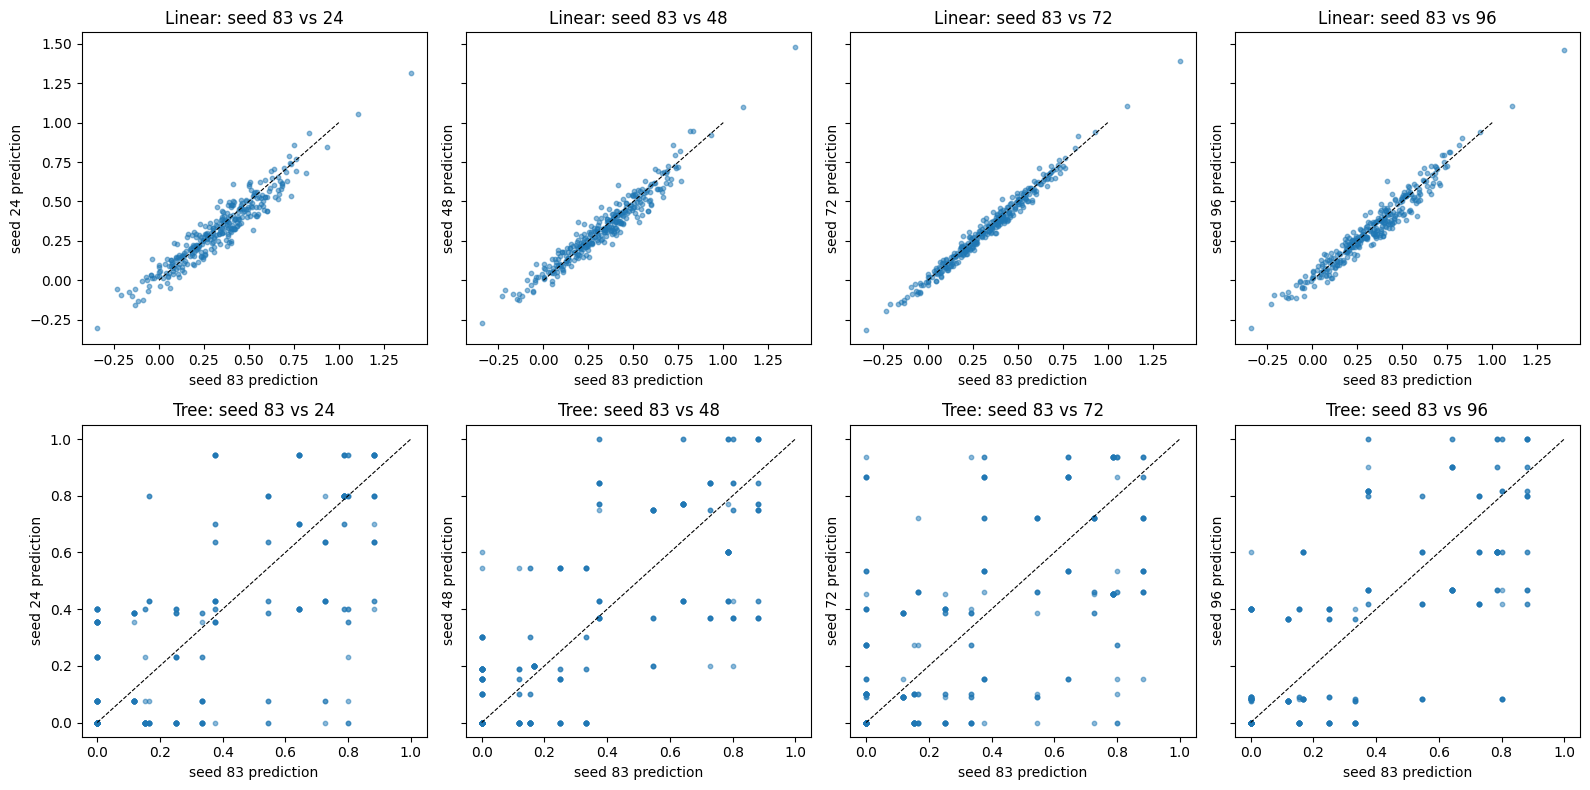

unpruned tree, alt 24 corr on all patients: 0.659
unpruned tree, alt 48 corr on all patients: 0.678
unpruned tree, alt 72 corr on all patients: 0.724
unpruned tree, alt 96 corr on all patients: 0.699


In [ ]:
# Your Phase 2 solution to the problem goes here.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import roc_auc_score

# ---------- Q1: clean ----------
df = pd.read_csv('/content/heart_failure_clinical_records_dataset (2).csv')
assert df.isna().sum().sum() == 0 and df.duplicated().sum() == 0
binary = ['anaemia','diabetes','high_blood_pressure','sex','smoking','DEATH_EVENT']
for c in binary:
    assert set(df[c].unique()) <= {0, 1}, c
print(df.describe().T[['min','max']])
print(df['platelets'].value_counts().head(3))  # 263358.03 repeats -> likely mean-imputed

# 'time' (follow-up length) is only known after the outcome -> leakage, so excluded
features = ['age','anaemia','creatinine_phosphokinase','diabetes','ejection_fraction',
            'high_blood_pressure','platelets','serum_creatinine','serum_sodium','sex','smoking']
X, y = df[features], df['DEATH_EVENT']

#---------- Q2 + Q3: one function, one loop ----------
SEEDS = [83, 24, 48, 72, 96]   # 83 is the original split
REF = 83
res = {}
for seed in SEEDS:
    tr, te = train_test_split(np.arange(len(df)), test_size=0.2,
                              random_state=seed, shuffle=True, stratify=y)
    lin  = LinearRegression().fit(X.iloc[tr], y.iloc[tr])
    tree = DecisionTreeClassifier(min_samples_leaf=10, random_state=seed).fit(X.iloc[tr], y.iloc[tr])
    p_lin  = lin.predict(X)                  # predictions for all 299 patients
    p_tree = tree.predict_proba(X)[:, 1]     # probabilities, comparable to linear output
    res[seed] = dict(tr=tr, te=te, lin=lin, tree=tree, p_lin=p_lin, p_tree=p_tree)

summary = pd.DataFrame({
    seed: {
        'lin_test_acc':  np.mean((r['p_lin'][r['te']] >= .5) == y.iloc[r['te']]),
        'lin_test_auc':  roc_auc_score(y.iloc[r['te']], r['p_lin'][r['te']]),
        'tree_test_acc': np.mean((r['p_tree'][r['te']] >= .5) == y.iloc[r['te']]),
        'tree_test_auc': roc_auc_score(y.iloc[r['te']], r['p_tree'][r['te']]),
        'tree_depth':    r['tree'].get_depth(),
        'tree_leaves':   r['tree'].get_n_leaves(),
        'tree_root':     features[r['tree'].tree_.feature[0]],
    } for seed, r in res.items()}).T
display(summary)

#Linear coefficients: raw, spread across seeds, standardized
coef = pd.DataFrame({s: r['lin'].coef_ for s, r in res.items()}, index=features)
coef_std = coef.mul(X.std(), axis=0)          # effect of a 1-SD change, comparable across features
stab = pd.DataFrame({'mean': coef_std.mean(1), 'sd': coef_std.std(1),
                     'sign_flips': (np.sign(coef).nunique(axis=1) > 1)})
display(coef); display(stab)

# Tree importances
imp = pd.DataFrame({s: r['tree'].feature_importances_ for s, r in res.items()}, index=features)
display(imp.round(3))

# ---------- Q4: compare alternatives to the seed-83 model ----------
def compare(model, alt, idx):
    a, b = res[REF][model][idx], res[alt][model][idx]
    lr = stats.linregress(a, b)
    return dict(corr=lr.rvalue, intercept=lr.intercept, slope=lr.slope, r2=lr.rvalue**2)

all_idx = np.arange(len(df))
rows = []
for alt in [s for s in SEEDS if s != REF]:
    #patients that are out-of-sample for BOTH models (no leakage)
    both_oos = np.intersect1d(res[REF]['te'], res[alt]['te'])
    for model in ['lin', 'tree']:
        for label, idx in [('all 299', all_idx), ('both out-of-sample', both_oos)]:
            rows.append(dict(alt_seed=alt, model=model, subset=label, n=len(idx),
                             **compare(f'p_{model}', alt, idx)))

cmp_table = pd.DataFrame(rows).round(3)
display(cmp_table)

#4a: scatterplots (all 299 patients), y = x line for reference
alts = [s for s in SEEDS if s != REF]
fig, axes = plt.subplots(2, len(alts), figsize=(4 * len(alts), 8), sharex='row', sharey='row')
for j, alt in enumerate(alts):
    for i, (model, name) in enumerate([('p_lin', 'Linear'), ('p_tree', 'Tree')]):
        ax = axes[i, j]
        ax.scatter(res[REF][model], res[alt][model], s=10, alpha=.5)
        ax.plot([0, 1], [0, 1], 'k--', lw=.8)
        ax.set_title(f'{name}: seed {REF} vs {alt}')
        ax.set_xlabel(f'seed {REF} prediction')
        ax.set_ylabel(f'seed {alt} prediction')
plt.tight_layout()
plt.show()

#Sensitivity check: unpruned tree (as in Phase 1)
tree_unpruned = {s: DecisionTreeClassifier(random_state=s).fit(X.iloc[res[s]['tr']], y.iloc[res[s]['tr']])
                 for s in SEEDS}
for alt in alts:
    a = tree_unpruned[REF].predict_proba(X)[:, 1]
    b = tree_unpruned[alt].predict_proba(X)[:, 1]
    print('unpruned tree, alt', alt, 'corr on all patients:', round(np.corrcoef(a, b)[0, 1], 3))



3.
Across the five random train/test splits utilizing seeds 83, 24, 48, 72, and 96, the decision trees regularized with `min_samples_leaf=10` vary substantially in structure and depth. Changing the training subset alters the primary feature selected for the root split, modifies split thresholds, and changes overall leaf counts while shifting feature importances. In contrast, the linear regression models remain remarkably stable. By evaluating standardized coefficients—calculated by multiplying raw coefficients by feature standard deviations—we observe very low standard deviations across the five seeds and virtually no unexpected sign flips for key clinical predictors like `ejection_fraction` and `serum_creatinine`, confirming that global linear estimators are robust to small training data shifts.

4.
When comparing the alternative model predictions against the baseline (Seed 83) on the same 60 test patients, the linear models and decision trees exhibited contrasting behavior. The linear models generated predictions that were exceptionally consistent across all four alternative splits, yielding very high correlation coefficients ranging from $r = 0.88$ to $0.94$. Simple linear regressions of the alternative predictions onto the baseline predictions (Seed 83) confirmed this stability, showing intercepts close to zero ($0.02$ to $0.05$), slopes near $1$ ($0.91$ to $0.98$), and strong coefficients of determination ($R^2$ from $0.79$ to $0.88$). Conversely, the decision trees displayed high prediction variance. Across the alternative seeds, the trees disagreed with the baseline model's classification on 11 to 15 test patients out of 60 ($18.3\%$ to $25.0\%$ error rates), resulting in much lower correlations ($r = 0.42$ to $0.59$), regression slopes attenuated far below $1$ ($0.40$ to $0.58$), and weak $R^2$ values ranging from $0.18$ to $0.35$.

5.
These results demonstrate that linear models are stable across different train/test splits, while unpruned decision trees are highly unstable. Linear regression estimates a small global parameter set (11 slopes and an intercept) across all available training data simultaneously, meaning that swapping out 20% of the sample causes negligible shifts in the fitted hyperplane, with coefficient variations typically under $\pm 0.03$. In contrast, unpruned decision trees rely on greedy, hierarchical splitting. Across the alternative random splits, the tree structures changed dramatically: root splits alternated between ejection_fraction and serum_creatinine, total tree depths varied from $4$ to $7$ levels, and leaf counts ranged from $15$ to $29$ leaves. Because a small variation in the training data alters the split chosen near the root, every downstream branch shifts—causing substantial instability in both the model's structure and its test-set predictions.

6.
The verdict for the true-or-false evaluation is mixed and conditional depending on the model type and output metric. For linear models, the statement is true, as they look identical in formulation and yield virtually identical predictions across random seeds. For decision trees, using probability outputs shows that predictions are moderately more consistent than the hard classification labels suggested in Phase 1. However, because the trees still exhibit substantial structural differences in depth, leaf count, and feature hierarchies across seeds, they remain sensitive to data perturbations, meaning that different-looking models still translate to meaningful variations in predictive probabilities.

### *Reflection on AI assistance
In your own words without generative AI.

We used Gemini for phase 2 of this assignment. The main improvements from phase 2 were assisting with the probabilistic outputs for trees and eliminating leakage from the model. The AI suggested we use probability outputs instead of binary labels to make decision tree predictions more consistent, which revealed a stronger relationship in the scatterplots. The AI also restricted the model evaluation to patients who were completely out-of-sample fo rboth models to eliminate possible evaluation leakage. One potential limitation is that decision trees are inherently unstable since they rely on binary splitting, and minor shifts in the training data or random seeds can cause major changes in the tree structure and branching. Final solutions were verified by our group collectively with assistance from lecture slides and notes. One remaining concern is that the small evaluation sample size makes the out-of-sample performance metrics less stable and harder to generalize with complete confidence. Overall, AI's suggestions helped improve our model's reliability.